# Counterfactual Scoring: Smart Carrier Recommendation

## Business objective

Recommend the best carrier for each shipment by combining the team's transit-time model and cost model. For every shipment we ask "what if we had used a different carrier?", predict the cost and the transit time for each option, and pick the cheapest one that still meets the delivery promise.

## Modeling plan

1. Load the processed data and use the same 70/15/15 split as the other model notebooks.
2. Work out which carrier/service options each shipment is allowed to use.
3. Train a transit model (P50 and P90 quantiles) and a cost model.
4. Swap every eligible carrier/service into each test shipment and score it (the counterfactual part).
5. Recommend the cheapest option whose P90 transit time is within the original promised days.
6. Compare the recommendation against what was actually shipped, and sanity check the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

In [2]:
df = pd.read_csv("../notebooks/engineered_features.csv", dtype={"origin_zip": str, "dest_zip": str})
df["lane"] = df["origin_metro"] + " -> " + df["dest_metro"]

print(f"Rows: {len(df):,}")
print(f"Duplicate shipment IDs: {df['shipment_id'].duplicated().sum():,}")
df.head()

Rows: 39,747
Duplicate shipment IDs: 0


,shipment_id,order_date,ship_date,ship_dow,ship_month,shipment_mode,carrier,service_level,origin_metro,dest_metro,origin_zip,dest_zip,origin_lat,origin_lon,dest_lat,dest_lon,distance_miles,zone,weight_lbs,length_in,width_in,height_in,pallet_count,residential_flag,signature_required,declared_value_usd,fuel_surcharge_pct,weather_severity,carrier_congestion_index,promised_days,carrier_cost_usd,transit_days,delivered_on_time,weight_lbs_na,length_in_na,width_in_na,height_in_na,lane
0,SHP-42-0003885,2024-04-23,2024-04-23,1,4,parcel,Cobalt Regional,Overnight,Los Angeles CA,Salt Lake City UT,90041,84137,34.05,-118.24,40.76,-111.89,579.60,4,2.48,7.50,4.30,6.50,0,1,0,0.00,0.10,0.11,0.00,2,29.53,1,1,False,False,False,False,Los Angeles CA -> Salt Lake City UT
1,SHP-42-0010239,2025-01-07,2025-01-09,3,1,parcel,Northstar Parcel,Expedited,Seattle WA,New York NY,98167,10067,47.61,-122.33,40.71,-74.01,"2,401.70",8,3.57,10.90,6.10,4.20,0,1,1,178.87,0.14,0.27,0.21,4,28.30,3,1,False,False,False,False,Seattle WA -> New York NY
2,SHP-42-0035486,2025-07-30,2025-07-30,2,7,ltl_freight,Vela Freight,LTL Standard,Atlanta GA,Miami FL,30358,33142,33.75,-84.39,25.76,-80.19,606.70,5,202.72,31.70,33.00,20.30,1,0,0,0.00,0.07,0.22,0.12,9,205.09,8,1,False,False,False,False,Atlanta GA -> Miami FL
3,SHP-42-0008180,2025-03-24,2025-03-26,2,3,parcel,Northstar Parcel,Ground,New York NY,Salt Lake City UT,10043,84144,40.71,-74.01,40.76,-111.89,"1,967.50",8,3.53,9.80,5.30,4.70,0,0,0,110.12,0.09,0.05,0.29,7,11.79,6,1,False,False,False,False,New York NY -> Salt Lake City UT
4,SHP-42-0015190,2025-05-06,2025-05-08,3,5,parcel,Falcon Post,Expedited,Los Angeles CA,Columbus OH,90058,43209,34.05,-118.24,39.96,-82.99,"1,974.00",8,6.39,7.10,6.20,7.70,0,0,0,14.83,0.12,0.27,0.12,4,13.13,6,0,False,False,False,False,Los Angeles CA -> Columbus OH


## 1. Train/validation/test split

Same split and seed as the transit and cost notebooks. The models learn from train, validation is used for early stopping, and the recommendations are made on the test set only.

In [3]:
SEED = 1234

train, holdout = train_test_split(df, test_size=0.30, random_state=SEED)
val, test = train_test_split(holdout, test_size=0.50, random_state=SEED)

print(f"Train: {len(train):,}  Validation: {len(val):,}  Test: {len(test):,}")

Train: 27,822  Validation: 5,962  Test: 5,963


## 2. Which options is each shipment allowed to use?

An option is a carrier + service level pair. The rules, all learned from the training set:

- Parcel shipments can only use parcel carriers/services, and LTL shipments only LTL ones.
- Only carrier/service pairs that exist in the training data are allowed.
- A carrier can only be used on lanes it has served before. This is what keeps Cobalt Regional on west/mountain lanes.

Each option also has its own promised days. In the data `promised_days` is the same for every shipment with the same lane, carrier and service, so we can look it up from the training set (and fall back to zone if that lane/carrier/service never showed up).

In [4]:
# valid carrier/service pairs for each mode
valid_options = train[["shipment_mode", "carrier", "service_level"]].drop_duplicates()
print(valid_options.groupby("shipment_mode").size())

# lanes each carrier has served
carrier_lanes = train[["lane", "carrier"]].drop_duplicates()
print("\nLanes served per carrier:")
print(carrier_lanes.groupby("carrier").size())

shipment_mode
ltl_freight     4
parcel         16
dtype: int64

Lanes served per carrier:
carrier
Cobalt Regional      30
Falcon Post         306
Ironclad Freight    305
Northstar Parcel    306
Summit Express      306
Vela Freight        301
dtype: int64


In [5]:
# promised days lookups (one value per group, checked below)
promise_by_lane = train.groupby(["lane", "carrier", "service_level"])["promised_days"].agg(["min", "max"])
promise_by_zone = train.groupby(["zone", "carrier", "service_level"])["promised_days"].agg(["min", "max"])
assert (promise_by_lane["min"] == promise_by_lane["max"]).all()
assert (promise_by_zone["min"] == promise_by_zone["max"]).all()

promise_by_lane = promise_by_lane["min"].rename("promise_lane").reset_index()
promise_by_zone = promise_by_zone["min"].rename("promise_zone").reset_index()

In [6]:
def build_options(shipments):
    shipments = shipments.reset_index(drop=True)
    shipments["ship_id"] = shipments.index

    # keep the original choice under separate names
    shipments = shipments.rename(columns={
        "carrier": "orig_carrier",
        "service_level": "orig_service",
        "promised_days": "orig_promised_days",
        "carrier_cost_usd": "orig_cost",
    })

    # every shipment x every valid option for its mode
    options = shipments.merge(valid_options, on="shipment_mode")
    options["is_current"] = (options["carrier"] == options["orig_carrier"]) & (options["service_level"] == options["orig_service"])

    # only keep carriers that serve the lane (the actual choice is always kept)
    options = options.merge(carrier_lanes.assign(serves_lane=True), on=["lane", "carrier"], how="left")
    options = options[(options["serves_lane"] == True) | options["is_current"]]

    # promised days for each option
    options = options.merge(promise_by_lane, on=["lane", "carrier", "service_level"], how="left")
    options = options.merge(promise_by_zone, on=["zone", "carrier", "service_level"], how="left")
    options["promised_days"] = options["promise_lane"].fillna(options["promise_zone"])
    options.loc[options["is_current"], "promised_days"] = options["orig_promised_days"]

    return options.drop(columns=["serves_lane", "promise_lane", "promise_zone"]).reset_index(drop=True)


test_options = build_options(test)

print(f"{len(test_options):,} options for {len(test):,} test shipments")
print("Options per shipment:")
print(test_options.groupby("ship_id").size().value_counts().sort_index())

assert test_options["promised_days"].notna().all()
assert (test_options.groupby("ship_id")["is_current"].sum() == 1).all()

66,196 options for 5,963 test shipments
Options per shipment:
2        5
3        2
4      857
12    4708
16     391
Name: count, dtype: int64


## 3. Transit and cost models

Both are CatBoost, like the existing notebooks.

- **Transit:** a multi-quantile model that predicts the median (P50) and the 90th percentile (P90) of `transit_days`. P90 is what we use for the "90% confident it arrives on time" rule.
- **Cost:** CatBoost with MAE loss on `carrier_cost_usd`.

One change from the transit notebook: **`carrier_cost_usd` is not a transit feature here**. When we swap carriers, that column would still hold the original carrier's price, which leaks which carrier the shipment really used into every counterfactual prediction. `promised_days` stays in because each option gets its own promised days.

In [7]:
categorical_features = ["shipment_mode", "carrier", "service_level", "origin_metro", "dest_metro"]

numeric_features = [
    "ship_dow", "ship_month", "distance_miles", "zone",
    "weight_lbs", "length_in", "width_in", "height_in", "pallet_count",
    "residential_flag", "signature_required", "declared_value_usd",
    "fuel_surcharge_pct", "weather_severity", "carrier_congestion_index",
    "promised_days",
]

features = categorical_features + numeric_features

# the target and the other outcome can never be features, and neither can cost (see above)
for banned in ["transit_days", "delivered_on_time", "carrier_cost_usd"]:
    assert banned not in features

In [8]:
quantile_loss = "MultiQuantile:alpha=0.5,0.9"

transit_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.08,
    depth=6,
    loss_function=quantile_loss,
    eval_metric=quantile_loss,
    early_stopping_rounds=100,
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
)
transit_model.fit(
    train[features], train["transit_days"],
    cat_features=categorical_features,
    eval_set=(val[features], val["transit_days"]),
)
print("Transit model trees:", transit_model.tree_count_)

Transit model trees: 237


In [9]:
cost_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=6,
    loss_function="MAE",
    eval_metric="MAE",
    early_stopping_rounds=100,
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
)
cost_model.fit(
    train[features], train["carrier_cost_usd"],
    cat_features=categorical_features,
    eval_set=(val[features], val["carrier_cost_usd"]),
)
print("Cost model trees:", cost_model.tree_count_)

Cost model trees: 2000


In [10]:
# quick check on the test set at the options that really happened
transit_preds = np.sort(transit_model.predict(test[features]), axis=1)   # sort so P50 <= P90
cost_preds = np.clip(cost_model.predict(test[features]), 0, None)

print(f"Transit P50 MAE: {np.abs(test['transit_days'] - transit_preds[:, 0]).mean():.3f} days "
      f"(promised-date baseline: {np.abs(test['transit_days'] - test['promised_days']).mean():.3f})")
print(f"Share of shipments at or under P90: {(test['transit_days'] <= transit_preds[:, 1]).mean():.3f} (should be about 0.90)")
print(f"Cost MAE: ${np.abs(test['carrier_cost_usd'] - cost_preds).mean():.2f}")

Transit P50 MAE: 0.531 days (promised-date baseline: 0.825)
Share of shipments at or under P90: 0.899 (should be about 0.90)
Cost MAE: $1.66


## 4. Counterfactual scoring

Now score every option for every test shipment. Everything about the shipment stays the same (lane, weight, weather, ship date...) except the carrier, service level and promised days. For each option we get:

- `pred_cost`: predicted cost in dollars
- `p50` and `p90`: predicted median and 90th percentile transit days

`deadline` is the shipment's **original promised days**. An option "meets the deadline" if its predicted P90 is no more than the deadline, meaning we are about 90% sure it arrives in time.

In [11]:
scored = test_options.copy()

scored["pred_cost"] = np.clip(cost_model.predict(scored[features]), 0, None)

quantiles = np.sort(transit_model.predict(scored[features]), axis=1)
scored["p50"] = quantiles[:, 0]
scored["p90"] = quantiles[:, 1]

scored["deadline"] = scored["orig_promised_days"]
scored["meets_deadline"] = scored["p90"] <= scored["deadline"]

scored[["shipment_id", "orig_carrier", "orig_service", "carrier", "service_level",
        "promised_days", "pred_cost", "p50", "p90", "deadline", "meets_deadline"]].head(10)

,shipment_id,orig_carrier,orig_service,carrier,service_level,promised_days,pred_cost,p50,p90,deadline,meets_deadline
0,SHP-42-0012354,Summit Express,Ground,Falcon Post,Ground,7.00,15.89,7.49,8.62,7,False
1,SHP-42-0012354,Summit Express,Ground,Northstar Parcel,Ground,7.00,19.12,6.52,7.33,7,False
2,SHP-42-0012354,Summit Express,Ground,Falcon Post,Expedited,4.00,19.07,4.95,5.98,7,True
3,SHP-42-0012354,Summit Express,Ground,Summit Express,Expedited,4.00,30.45,3.35,3.87,7,True
4,SHP-42-0012354,Summit Express,Ground,Northstar Parcel,Overnight,2.00,41.67,2.42,3.29,7,True
5,SHP-42-0012354,Summit Express,Ground,Northstar Parcel,TwoDay,3.00,27.69,3.58,4.38,7,True
6,SHP-42-0012354,Summit Express,Ground,Summit Express,Overnight,2.00,53.13,1.81,2.33,7,True
7,SHP-42-0012354,Summit Express,Ground,Falcon Post,Overnight,2.00,31.76,3.30,4.45,7,True
8,SHP-42-0012354,Summit Express,Ground,Summit Express,Ground,7.00,24.87,5.86,6.46,7,True
9,SHP-42-0012354,Summit Express,Ground,Summit Express,TwoDay,3.00,34.37,2.94,3.47,7,True


## 5. Sanity checks

We can't see the true outcome for options that weren't used, so check that the scores behave sensibly:

1. For the option that was actually used, the predictions should be as good as the standalone models.
2. Faster services should cost more and have shorter predicted transit.
3. Carriers should differ the way the data dictionary says (Summit fast and expensive, Falcon cheap and slower).

In [12]:
actual = scored[scored["is_current"]].sort_values("ship_id")
test_sorted = test.reset_index(drop=True)

print(f"Cost MAE at the actual option: ${np.abs(test_sorted['carrier_cost_usd'] - actual['pred_cost'].values).mean():.2f}")
print(f"Transit P50 MAE at the actual option: {np.abs(test_sorted['transit_days'] - actual['p50'].values).mean():.3f} days")
print(f"Share at or under P90: {(test_sorted['transit_days'] <= actual['p90'].values).mean():.3f}")

Cost MAE at the actual option: $1.66
Transit P50 MAE at the actual option: 0.531 days
Share at or under P90: 0.899


In [13]:
# every shipment is scored under every option, so these averages compare options fairly
parcel = scored[scored["shipment_mode"] == "parcel"]
service_order = ["Overnight", "TwoDay", "Expedited", "Ground"]

option_summary = parcel.groupby(["service_level", "carrier"])[["pred_cost", "p50", "p90"]].mean()
display(option_summary.reindex(service_order, level=0))

by_service = parcel.groupby("service_level")[["pred_cost", "p50"]].mean().reindex(service_order)
assert by_service["p50"].is_monotonic_increasing
assert by_service["pred_cost"].is_monotonic_decreasing

pred_cost  p50  p90
service_level carrier                              
Overnight     Cobalt Regional       29.58 1.61 2.28
              Falcon Post           28.23 3.03 3.97
              Northstar Parcel      34.48 2.12 2.92
              Summit Express        46.58 1.43 2.01
TwoDay        Cobalt Regional       21.76 2.66 3.26
              Falcon Post           20.11 4.09 5.11
              Northstar Parcel      24.43 3.14 3.95
              Summit Express        32.75 2.46 3.08
Expedited     Cobalt Regional       18.02 2.96 3.55
              Falcon Post           16.32 4.48 5.46
              Northstar Parcel      19.95 3.61 4.42
              Summit Express        25.74 2.87 3.47
Ground        Cobalt Regional       14.32 4.73 5.36
              Falcon Post           13.22 6.58 7.59
              Northstar Parcel      16.04 5.66 6.45
              Summit Express        20.94 4.98 5.60

## 6. Recommending a carrier

For each shipment, among its options:

1. Keep the options that meet the deadline (P90 <= original promised days).
2. Choose the cheapest one.
3. If no option meets the deadline, choose the one with the lowest P90 instead.

Two versions:

- **Carrier only:** keep the service level the customer picked and only change the carrier.
- **Carrier + service:** allow any carrier and any service level.

For comparison we also look at what was actually shipped, the cheapest option with no constraint, and the fastest option.

In [14]:
def recommend(options):
    options = options.copy()
    # options that meet the deadline are ranked by cost, the rest are ranked after them by P90
    options["rank_score"] = np.where(options["meets_deadline"], options["pred_cost"], 1_000 + options["p90"])
    best = options.sort_values(["ship_id", "rank_score"]).groupby("ship_id").head(1)
    return best.set_index("ship_id").sort_index()


same_service = scored[scored["service_level"] == scored["orig_service"]]

rec_carrier = recommend(same_service)
rec_both = recommend(scored)

current = scored[scored["is_current"]].set_index("ship_id").sort_index()
cheapest = scored.sort_values(["ship_id", "pred_cost"]).groupby("ship_id").head(1).set_index("ship_id").sort_index()
fastest = scored.sort_values(["ship_id", "p50"]).groupby("ship_id").head(1).set_index("ship_id").sort_index()

print(f"No option meets the deadline (carrier only): {(~rec_carrier['meets_deadline']).mean():.1%} of shipments")
print(f"No option meets the deadline (carrier + service): {(~rec_both['meets_deadline']).mean():.1%} of shipments")

No option meets the deadline (carrier only): 29.3% of shipments
No option meets the deadline (carrier + service): 7.9% of shipments


In [15]:
policies = {
    "Current (as shipped)": current,
    "Cheapest, no constraint": cheapest,
    "Fastest": fastest,
    "Recommended: carrier only": rec_carrier,
    "Recommended: carrier + service": rec_both,
}

rows = []
for name, policy in policies.items():
    rows.append({
        "Policy": name,
        "Avg predicted cost": policy["pred_cost"].mean(),
        "Avg predicted P50 days": policy["p50"].mean(),
        "Avg predicted P90 days": policy["p90"].mean(),
        "% meeting deadline": 100 * policy["meets_deadline"].mean(),
        "% changed from current": 100 * (~policy["is_current"]).mean(),
    })

policy_summary = pd.DataFrame(rows).set_index("Policy")
policy_summary

,Avg predicted cost,Avg predicted P50 days,Avg predicted P90 days,% meeting deadline,% changed from current
Policy,,,,,
Current (as shipped),60.99,5.29,6.11,25.74,0.00
"Cheapest, no constraint",52.99,6.85,7.85,5.18,75.78
Fastest,86.45,2.19,2.78,92.12,96.14
Recommended: carrier only,67.81,4.62,5.27,70.65,70.82
Recommended: carrier + service,63.86,4.09,4.90,92.12,87.71


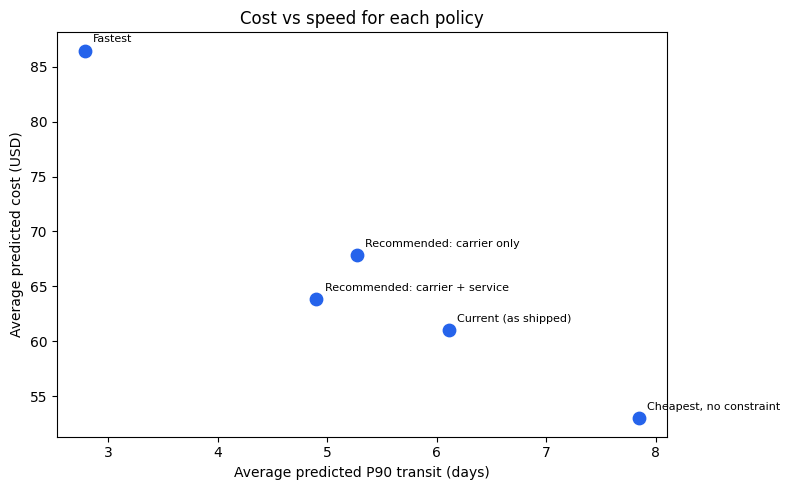

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(policy_summary["Avg predicted P90 days"], policy_summary["Avg predicted cost"], s=80, color="#2563eb")
for name, row in policy_summary.iterrows():
    ax.annotate(name, (row["Avg predicted P90 days"], row["Avg predicted cost"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set(title="Cost vs speed for each policy", xlabel="Average predicted P90 transit (days)", ylabel="Average predicted cost (USD)")
plt.tight_layout()
plt.show()

## 7. Where do the savings (and extra costs) come from?

Only a small share of shipments meet their deadline at P90 with the carrier they actually used, so the constraint pushes a lot of shipments to a more reliable (and usually more expensive) carrier. Splitting by whether the current option already meets the deadline shows this.

In [17]:
change = pd.DataFrame({
    "current_meets_deadline": current["meets_deadline"],
    "switched": ~rec_carrier["is_current"],
    "cost_change": rec_carrier["pred_cost"] - current["pred_cost"],
})

by_current = change.groupby("current_meets_deadline").agg(
    shipments=("switched", "size"),
    pct_switched=("switched", lambda s: 100 * s.mean()),
    avg_cost_change=("cost_change", "mean"),
    total_cost_change=("cost_change", "sum"),
)
display(by_current)

total_change = change["cost_change"].sum()
print(f"Total predicted cost change on the test set: ${total_change:,.0f} ({100 * total_change / current['pred_cost'].sum():+.1f}%)")

,shipments,pct_switched,avg_cost_change,total_cost_change
current_meets_deadline,,,,
False,4428,88.66,9.69,"42,913.04"
True,1535,19.35,-1.45,"-2,225.59"


Total predicted cost change on the test set: $40,687 (+11.2%)


In [18]:
carrier_mix = pd.DataFrame({
    "current": current.groupby("carrier").size(),
    "recommended (carrier only)": rec_carrier.groupby("carrier").size(),
}).fillna(0).astype(int)
carrier_mix["change"] = carrier_mix["recommended (carrier only)"] - carrier_mix["current"]
carrier_mix

,current,recommended (carrier only),change
carrier,,,
Cobalt Regional,177,220,43
Falcon Post,2061,0,-2061
Ironclad Freight,505,81,-424
Northstar Parcel,1672,954,-718
Summit Express,1189,3925,2736
Vela Freight,359,783,424


## 8. Checking against real outcomes

We can't check the model's predictions for options that weren't used, but we can look at real data:

1. In the training data, how often did shipments with the recommended carrier, service and zone arrive within the original deadline? This uses no model at all.
2. For shipments where the recommended option is the one that really shipped, how often was the real transit within the predicted P90?

In [19]:
# 1. historical on-time rate by carrier/service/zone, measured against each shipment's deadline
def historical_on_time(policy):
    history = train[["carrier", "service_level", "zone", "transit_days"]]
    merged = policy.reset_index()[["ship_id", "carrier", "service_level", "zone", "deadline"]].merge(
        history, on=["carrier", "service_level", "zone"], how="left")
    merged["on_time"] = merged["transit_days"] <= merged["deadline"]
    return merged.groupby("ship_id")["on_time"].mean()

hist = pd.DataFrame({
    "current": historical_on_time(current),
    "recommended (carrier only)": historical_on_time(rec_carrier),
    "recommended (carrier + service)": historical_on_time(rec_both),
})
print("Historical on-time rate against the original deadline (training data):")
display(hist.mean().to_frame("on-time rate"))

Historical on-time rate against the original deadline (training data):


,on-time rate
current,0.73
recommended (carrier only),0.94
recommended (carrier + service),0.96


In [20]:
# 2. where recommendation == what actually shipped we have the real transit time
agree = rec_carrier["is_current"]
print(f"Recommendation matches the actual option for {agree.mean():.1%} of shipments")
print(f"Real transit within predicted P90 on those: {(test_sorted.loc[agree, 'transit_days'] <= rec_carrier.loc[agree, 'p90']).mean():.3f}")

Recommendation matches the actual option for 29.2% of shipments
Real transit within predicted P90 on those: 0.880


## 9. Example recommendations

Three shipments where the recommendation differs from what was actually used, with all carrier options at the original service level.

In [21]:
switched_ids = rec_carrier[~rec_carrier["is_current"]].sample(3, random_state=SEED).index

for ship_id in switched_ids:
    row = test_sorted.loc[ship_id]
    print(f"{row['shipment_id']}: {row['lane']}, {row['weight_lbs']:.0f} lbs, {row['service_level']}, deadline {row['promised_days']} days")

    options = same_service[same_service["ship_id"] == ship_id].copy()
    options["recommended"] = options["carrier"] == rec_carrier.loc[ship_id, "carrier"]
    display(options.sort_values("pred_cost")[["carrier", "pred_cost", "p50", "p90", "meets_deadline", "is_current", "recommended"]])

SHP-42-0006696: Atlanta GA -> Portland OR, 3 lbs, Ground, deadline 7 days


,carrier,pred_cost,p50,p90,meets_deadline,is_current,recommended
12400,Falcon Post,13.36,8.20,9.28,False,True,False
12401,Northstar Parcel,16.14,7.30,8.11,False,False,False
12408,Summit Express,20.98,6.48,7.16,False,False,True


SHP-42-0031832: Houston TX -> Chicago IL, 471 lbs, Ground, deadline 6 days


,carrier,pred_cost,p50,p90,meets_deadline,is_current,recommended
8256,Falcon Post,9.64,6.17,7.09,False,False,False
8257,Northstar Parcel,12.03,5.17,5.92,True,False,True
8264,Summit Express,15.54,4.54,5.18,True,True,False


SHP-42-0043866: Boston MA -> Portland OR, 471 lbs, Ground, deadline 7 days


,carrier,pred_cost,p50,p90,meets_deadline,is_current,recommended
2268,Falcon Post,13.14,7.70,8.68,False,False,False
2269,Northstar Parcel,15.96,6.78,7.55,False,True,False
2276,Summit Express,21.72,5.97,6.58,True,False,True


## 10. Results

Test set, `SEED = 1234` (5,963 shipments, about 66,000 scored options):

| Policy | Avg predicted cost | Avg predicted P90 days | % meeting deadline |
|---|---|---|---|
| Current (as shipped) | $60.99 | 6.11 | 25.7% |
| Cheapest, no constraint | $52.99 | 7.85 | 5.2% |
| Recommended: carrier only | $67.81 | 5.27 | 70.7% |
| Recommended: carrier + service | $63.86 | 4.90 | 92.1% |
| Fastest | $86.45 | 2.78 | 92.1% |

- **The scores pass the sanity checks.** At the options that really shipped, cost MAE is $1.66, P50 transit MAE is 0.531 days and 89.9% of real transit times are at or under P90. Faster services cost more and have shorter predicted transit, and carriers differ the way the data dictionary says.
- **Most current shipments are risky against their promise.** Only about a quarter meet their deadline at P90, mostly because of Falcon Post (cheap but often late). The carrier-only recommendation stops using Falcon Post completely.
- **The 90% rule costs money.** Changing only the carrier raises predicted spend by about 11% ($60.99 to $67.81 per shipment), and the share meeting the deadline goes from 26% to 71%. The historical on-time rate in the training data goes from 0.73 to 0.94 for the recommended carriers.
- **Savings exist, but they are small.** For shipments whose current option already meets the deadline, switching saves about $1.45 per shipment on average.
- **Letting the service level change is the better trade-off.** Carrier + service reaches 92% meeting the deadline for only about 5% more cost than today. The "fastest" option reaches the same 92% but costs about 42% more.
- **Limit of the checks.** Where the recommendation matches what really shipped, 88% of real transit times were within P90, slightly under 90%, and that subset is selected by the recommendation, so it is only a rough check. Seven test shipments are on lanes with few or no other carriers in the training data, so they have only 2-3 options.

## 11. Limitations

- The predictions for options that were not used are extrapolations. Nobody observed what Summit would have charged or how fast it would have been on a shipment Falcon carried. If carriers were assigned to shipments in a way our features don't capture, the counterfactuals are biased. Real validation would need an A/B test.
- The cost model predicts the billed `carrier_cost_usd`, not a live rate quote.
- Promised days for other carriers come from the training data, not a live carrier SLA.
- The P90 rule is strict. Using a looser confidence level or allowing a day of slack would change the trade-off, and which one to use is a business decision.
- Like the other notebooks, this is a random split, not a time-ordered one, so peak season behavior is untested.